# Palmer Penguins
## Understanding the data and exploratory analysis

Author: Marcos Robinat. Courses: PRDL and MLLB, 2026-2027.

This notebook explains the observation, all eight variables, data provenance and quality, the fixed training/test allocation, and training-only exploratory analysis. Each analysis connects a question, visible code, a figure or table, and its interpretation.

The original CSV is unchanged. No model or learned preprocessing is fitted here. Notebook 02 contains the executed classification, regression and limited tree-depth search; the end of this notebook summarises the preparation and evaluation used there. The 69 reserved observations stay outside analytical EDA and model selection.

Run from the top with the original penguins.csv. Read the definitions and interpretations; the charts alone do not show predictive performance. All project explanations are in English.

### How to use this notebook

Run cells from top to bottom with **Shift + Enter**, reading the explanation before each code cell. In Colab, choose a standard CPU runtime. When asked, select the `penguins.csv` stored beside this notebook in Drive. That upload creates a temporary runtime copy; it does not change the Drive original. No access to your whole Drive is required.

In VS Code, open this folder, select a Python kernel with pandas, Matplotlib and scikit-learn, and run the same notebook with `penguins.csv` in the working directory. Colab may discard uploaded files after a runtime reset, so upload the same CSV again if needed.

Finish with the summary and the link to supervised learning. There are no models hidden behind helper scripts.

## 1. The observation and the learning tasks

A row is one recorded penguin observation. A column is a variable describing that observation. For classification, `species` is the target, and four physical measurements are the initial predictors. The three possible species are Adélie, Chinstrap and Gentoo.

Notebook 02 also predicts `body_mass_g` from the other three physical measurements, so mass is removed from the regression inputs. Unsupervised learning is planned as a separate notebook; it will study physical profiles without using species labels during fitting. It has not yet been run.

**Statistical-learning vocabulary:** an input is also called a predictor, feature or explanatory variable; the output is the response or target. Classification predicts a qualitative response (species). Regression predicts a quantitative response (mass in grams). Unsupervised learning studies structure in the inputs without providing a response during fitting. A useful predictor need not be a biological cause, and an association in this sample is not a causal effect.

## 2. Where the data come from

We use the authors' **simplified `penguins` table**, not the 17-column `penguins_raw` table. The authors document 344 observations and eight variables, collected near Palmer Station, Antarctica, in 2007–2009. This simplification was done by the data authors, not by us.

- Documentation and licence (CC0): https://allisonhorst.github.io/palmerpenguins/
- Variable definitions: https://allisonhorst.github.io/palmerpenguins/reference/penguins.html
- Downloaded CSV: https://raw.githubusercontent.com/allisonhorst/palmerpenguins/refs/heads/main/inst/extdata/penguins.csv
- Package citation: Horst, Hill and Gorman (2020), https://doi.org/10.5281/zenodo.3960218
- Original ecological study: Gorman, Williams and Fraser (2014), https://doi.org/10.1371/journal.pone.0090081

The CSV was acquired on **23 October 2026**. We record its SHA-256 fingerprint below because a URL on the `main` branch can change. The original measurements will not be overwritten.

## 3. Import the tools

`pandas` represents the CSV as a DataFrame, a labelled table. `Path` locates the file. `hashlib` checks the file fingerprint. Printing the Python and pandas versions tells us which environment produced the outputs. Matplotlib and scikit-learn are imported later for plots and splitting, not model fitting.

In [1]:
from pathlib import Path
import hashlib
import platform
import pandas as pd
from IPython.display import display

print('Python:', platform.python_version())
print('pandas:', pd.__version__)

Python: 3.12.14
pandas: 2.3.3


## 4. Load the unchanged CSV

The loader checks that we selected the exact file acquired for the project. In Colab, use the upload button if it appears. `read_csv` treats the source's `NA` markers as missing values. It does not fill them or remove observations. The fingerprint identifies bytes, not scientific quality.

In [2]:
DATA_PATH = Path('penguins.csv')
EXPECTED_SHA256 = 'f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93'

if not DATA_PATH.exists():
    try:
        from google.colab import files
    except ImportError as error:
        raise FileNotFoundError('Place penguins.csv in the notebook working directory.') from error
    print('Select the original penguins.csv from the Penguins_ML folder.')
    files.upload()

source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if source_hash != EXPECTED_SHA256:
    raise ValueError('The CSV differs from the recorded source. Check the file before continuing.')

penguins = pd.read_csv(DATA_PATH, na_values=['NA'])
print('CSV bytes:', DATA_PATH.stat().st_size)
print('SHA-256:', source_hash)
print('Rows:', penguins.shape[0], '| Columns:', penguins.shape[1])

CSV bytes: 15241
SHA-256: f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93
Rows: 344 | Columns: 8


## 5. Read a few observations

`head(5)` shows the first five rows in source order. They are an orientation example, **not a random or representative sample**. The left-hand index is a pandas row label, not an additional measured variable or a predictor. A missing value is not a zero.

The preview connects each recorded species and location to its measurements and units.

In [3]:
display(penguins.head(5))

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## 6. Understand the eight variables

| Column | Meaning and unit | Initial classification role |
|---|---|---|
| `species` | Recorded species | Target |
| `island` | Island of observation | Context; candidate for a later comparison |
| `bill_length_mm` | Bill length in millimetres | Predictor |
| `bill_depth_mm` | Bill depth in millimetres | Predictor |
| `flipper_length_mm` | Flipper length in millimetres | Predictor |
| `body_mass_g` | Body mass in grams | Predictor |
| `sex` | Recorded sex | Context; candidate for a later comparison |
| `year` | Observation year | Context; candidate for a later comparison |

Context columns are retained, not deleted. Leaving them outside the first model is a scope decision, not a claim that they are irrelevant. Millimetres and grams are different scales. Notebook 02 explains which algorithms use scaling and why.

All eight variables are studied below. The four physical measures define our first feature set, not a final selection. Species is the response, never a classifier input. Sex, island and year remain potential inputs for a later, explicitly justified comparison within training.

## 7. Inspect how Python represents the columns

A data type describes storage, not the scientific role of a variable. `year` is stored numerically but is not a body measurement. Text columns may appear as `object` or `str` depending on pandas. Missing measurements can make an integer-like column appear as floating point. None of these observations alone justifies changing the source.

In [4]:
display(penguins.dtypes.astype(str).rename('pandas_dtype').to_frame())

,pandas_dtype
species,object
island,object
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object
year,int64


## 8. Count missing cells without treating them

`isna()` marks missing entries. Summing by column counts missing **cells**; counting rows with any missing entry answers a different question. The percentage below uses all loaded rows as its denominator. This is an ingestion check across the source table, not an analysis of predictor–target relationships.

We will not run a blanket `dropna()` or fill every blank. Missing `sex`, currently a context column, does not by itself require excluding an otherwise usable classification observation. The reason for each absence is not established by this count.

In [5]:
missing = pd.DataFrame({
    'missing_cells': penguins.isna().sum(),
    'missing_percent': penguins.isna().mean().mul(100).round(2),
})
display(missing)
print('Missing cells in total:', int(penguins.isna().sum().sum()))
print('Rows with at least one missing cell:', int(penguins.isna().any(axis=1).sum()))
print('Rows with no missing cells:', int(penguins.notna().all(axis=1).sum()))

,missing_cells,missing_percent
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


Missing cells in total: 19
Rows with at least one missing cell: 11
Rows with no missing cells: 333


## 9. Check exact duplicate rows

`duplicated()` checks repeated combinations of all eight column values. A zero count does **not** prove that observations are independent or that the same individual could not appear elsewhere. The simplified table has no individual identifier. We are checking exact repeated rows, not resolving biological identity.

In [6]:
print('Exact duplicate rows:', int(penguins.duplicated().sum()))

Exact duplicate rows: 0


## 10. Separate the prediction question from the answer

We name the four initial input columns and the target explicitly. `X` contains measurements, while `y` contains species labels. This only selects columns: it does not fit a model, clean missing values or split the sample. Missing measurements remain present. For regression in notebook 02, these roles are redefined rather than reusing the classification inputs unchanged.

In notation, the input vector for observation $i$ is $x_i=(x_{i1},x_{i2},x_{i3},x_{i4})$ and the response is $y_i$. The matrix `X` places input vectors in rows. A fitted classifier estimates class probabilities from these measurements and then assigns a label. For the continuous-response task in notebook 02, a familiar model is $Y=f(X)+\epsilon$: it separates systematic information from unexplained variation. We do not treat a species name as a continuous numeric response.

In [7]:
FEATURES = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
TARGET = 'species'

X = penguins[FEATURES].copy()
y = penguins[TARGET].copy()
print('Predictors:', FEATURES)
print('Target:', TARGET)
print('X shape:', X.shape, '| y shape:', y.shape)
print('Target included in X:', TARGET in X.columns)

Predictors: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
Target: species
X shape: (344, 4) | y shape: (344,)
Target included in X: False


### Ingestion summary

The source contains 344 observations and eight variables, 19 missing cells in 11 rows and no exact duplicate rows. These whole-table ingestion checks preceded the split. They do not establish independent sampling or predictive performance. No source value is filled or removed. The following analyses use training only.

## 11. Reserve a final test before analytical EDA

**Question:** which observations may guide our decisions?

We assign 80% to training and 20% to a final test, using seed 42 and stratification by species. Stratification approximately preserves the class proportions; it does not balance the classes artificially. Labels are used here only to allocate the split. Original zero-based CSV row positions identify observations, not biological individuals and not predictors.

All subsequent tables and figures in this notebook use `train` only. The final test is reserved for one final evaluation after model choices. Notebook 02 uses five-fold cross-validation within training for model comparison and the limited depth search. An ordinary random split estimates performance within this sampled setting, not transfer to unseen years, islands or populations. Earlier whole-table ingestion checks are disclosed above, so we do not claim the test has never been inspected in any way.

Reference: [scikit-learn train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) and [avoiding data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [8]:
from sklearn.model_selection import train_test_split
import sklearn
import matplotlib.pyplot as plt

SEED = 42
train_ids, test_ids = train_test_split(
    penguins.index.to_numpy(),
    test_size=0.20,
    random_state=SEED,
    stratify=penguins[TARGET],
)
train_ids = sorted(int(i) for i in train_ids)
test_ids = sorted(int(i) for i in test_ids)
assert set(train_ids).isdisjoint(test_ids)
assert sorted(train_ids + test_ids) == list(penguins.index)
train = penguins.loc[train_ids].copy()
# Do not construct a test feature table or use it for EDA.
print(f'Training: {len(train_ids)} observations')
print(f'Final test reserved: {len(test_ids)} observations')
print('scikit-learn:', sklearn.__version__)
print('Split row IDs are reproducible from the unchanged CSV and this cell.')

Training: 275 observations
Final test reserved: 69 observations
scikit-learn: 1.9.1
Split row IDs are reproducible from the unchanged CSV and this cell.


## 12. Training composition

**Question:** how many training observations belong to each species?

Count each training label once and divide by the 275 training observations. The plot shows sample composition, not accuracy or an estimate of the species distribution across Antarctica.

,observations,percent
species,,
Adelie,122,44.36
Chinstrap,54,19.64
Gentoo,99,36.00


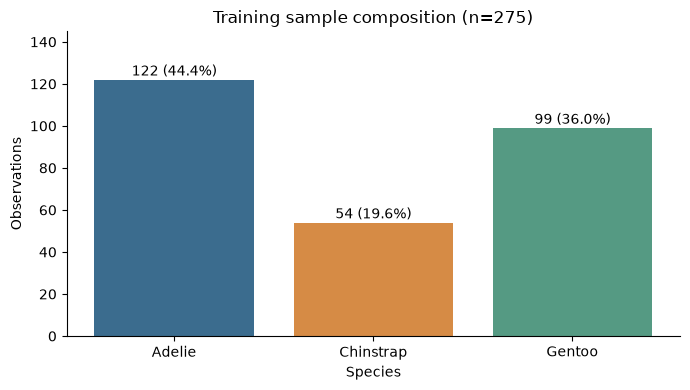

In [9]:
species_order = ['Adelie', 'Chinstrap', 'Gentoo']
composition = train[TARGET].value_counts().reindex(species_order).rename('observations').to_frame()
composition['percent'] = composition['observations'] / len(train) * 100
display(composition.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(composition.index, composition['observations'], color=['#3B6C8E', '#D68B45', '#559A83'])
for bar, count, percent in zip(bars, composition['observations'], composition['percent']):
    ax.text(bar.get_x() + bar.get_width()/2, count + 2, f'{count} ({percent:.1f}%)', ha='center')
ax.set(title=f'Training sample composition (n={len(train)})', xlabel='Species', ylabel='Observations')
ax.set_ylim(0, 145)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

**Interpretation.** Training contains 122 Adelie (44.36%), 54 Chinstrap (19.64%) and 99 Gentoo (36.00%) observations. Chinstrap has less than half as many examples as Adelie. Overall accuracy alone could hide poorer performance for this smaller class. Notebook 02 therefore also reports errors for each species. This finding does not justify oversampling or class weighting.

## 13. Training quality and missing values

**Question:** which absences affect the intended classifier inputs?

The denominator below is training only. A missing cell is not a zero. We inspect both missing cells per variable and affected rows, because several missing cells may belong to the same observation. We retain every row for inspection; no imputation, deletion or scaling is performed.

,pandas_dtype,missing_cells,missing_percent
species,object,0,0.00
island,object,0,0.00
bill_length_mm,float64,2,0.73
bill_depth_mm,float64,2,0.73
flipper_length_mm,float64,2,0.73
body_mass_g,float64,2,0.73
sex,object,11,4.00
year,int64,0,0.00


Missing cells: 19
Rows with any missing value: 11
Rows with all eight variables complete: 264
Rows with incomplete classifier inputs: 2
Rows with complete classifier inputs: 273
Exact duplicate training rows: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
source_row,,,,,,,,
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN,2007
178,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN,2007
218,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN,2008
256,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN,2009


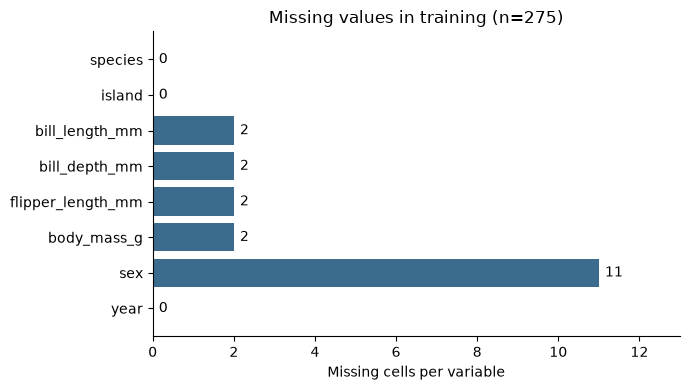

In [10]:
quality = pd.DataFrame({
    'pandas_dtype': train.dtypes.astype(str),
    'missing_cells': train.isna().sum(),
    'missing_percent': train.isna().mean() * 100,
})
display(quality.round(2))
missing_any = train.isna().any(axis=1)
missing_inputs = train[FEATURES].isna().any(axis=1)
print('Missing cells:', int(train.isna().sum().sum()))
print('Rows with any missing value:', int(missing_any.sum()))
print('Rows with all eight variables complete:', int((~missing_any).sum()))
print('Rows with incomplete classifier inputs:', int(missing_inputs.sum()))
print('Rows with complete classifier inputs:', int((~missing_inputs).sum()))
print('Exact duplicate training rows:', int(train.duplicated().sum()))
display(train.loc[missing_any].rename_axis('source_row'))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(quality.index, quality['missing_cells'], color='#3B6C8E')
for bar, count in zip(bars, quality['missing_cells']):
    ax.text(count + 0.15, bar.get_y() + bar.get_height()/2, str(count), va='center')
ax.invert_yaxis()
ax.set(title=f'Missing values in training (n={len(train)})', xlabel='Missing cells per variable', xlim=(0, 13))
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

**Interpretation.** There are 19 missing training cells across 11 rows (4.00% of training). Each physical measurement is absent twice (0.73%); those absences coincide in source rows 3 and 271. Recorded sex is absent in 11 rows (4.00%), including these two. Thus 264 rows have all eight variables present, but 273 have all four proposed classifier inputs present. A blanket `dropna()` would unnecessarily remove nine additional observations from that classifier. This is an observation about this split, not an explanation of why data are absent or proof that missingness is random.

No exact duplicate training rows were found. Without individual identifiers or sampling details this does not prove independent observations. Notebook 02 excludes these two rows only from its task-specific modelling views and keeps the original CSV unchanged. If imputation were added, its values would have to be learned within each cross-validation fit subset.

## 14. Exploring all variables is not the same as selecting all inputs

We study all eight columns. The four physical measurements answer the initial question: can we recognise species from morphology? The other three descriptive columns are not discarded or declared useless. They may be candidate predictors if they match the intended use and are available at prediction time.

There are three separate questions:

1. **Validity:** does the input make sense for the question and avoid revealing the answer?
2. **Association:** what relationships appear in training data?
3. **Predictive contribution:** does it improve a model under validation within training? We have not tested this yet.

A low linear correlation does not rule out nonlinear relationships or useful combinations. A p-value is not an effect size or a measure of predictive improvement. A t-test answers a specific hypothesis about means under assumptions; it is not a generic selector for a three-class species label. We will not assign arbitrary numeric species codes and interpret their Pearson correlation. No significance test or automatic variable selection is needed for the descriptive questions below.

**Prediction versus inference:** descriptive tables help understand the sample; hypothesis tests address specified assumptions and null hypotheses; held-out validation addresses predictive performance. These are related but different questions. Statistical significance alone does not decide which inputs a classifier should use.

## 15. Context and species: island, recorded sex and year

**Question:** what do the remaining variables tell us about the observed sample?

For each context variable we count species within each group. Percentages use the **row total**: a value describes the species composition within that island, sex category or year, not the distribution of that context within a species. Counts are shown alongside percentages so that small groups remain visible.

`Not recorded` is a display label for missing sex, not an imputation of biological sex. Source values and training rows are unchanged. Year is treated as a grouping variable here, not as a continuous physical measurement. All tables and charts below use only the same 275 training observations.


island: training counts


species,Adelie,Chinstrap,Gentoo,total
island,,,,
Biscoe,35,0,99,134
Dream,44,54,0,98
Torgersen,43,0,0,43


Species composition within each row (%)


species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,26.12,0.0,73.88
Dream,44.90,55.1,0.00
Torgersen,100.00,0.0,0.00



sex: training counts


species,Adelie,Chinstrap,Gentoo,total
sex,,,,
Not recorded,6,0,5,11
female,58,26,46,130
male,58,28,48,134


... (2 outputs left out)


year: training counts


species,Adelie,Chinstrap,Gentoo,total
year,,,,
2007,43,20,27,90
2008,37,12,35,84
2009,42,22,37,101


Species composition within each row (%)


species,Adelie,Chinstrap,Gentoo
year,,,
2007,47.78,22.22,30.00
2008,44.05,14.29,41.67
2009,41.58,21.78,36.63


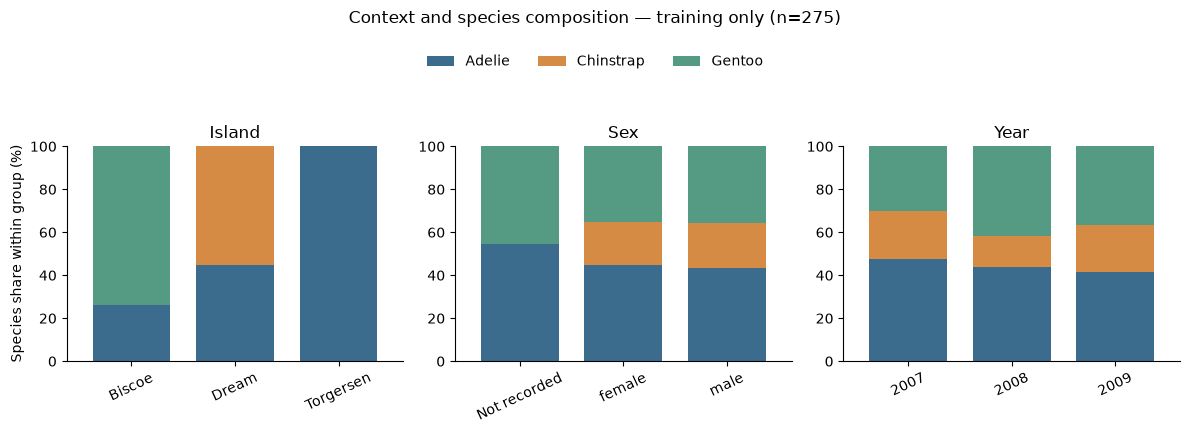

In [11]:
CONTEXT = ['island', 'sex', 'year']
context_counts = {}
context_percent = {}
for variable in CONTEXT:
    labels = train[variable].fillna('Not recorded')
    counts = pd.crosstab(labels, train[TARGET]).reindex(columns=species_order, fill_value=0)
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100
    assert int(counts.to_numpy().sum()) == len(train)
    context_counts[variable] = counts
    context_percent[variable] = percentages
    print(f'\n{variable}: training counts')
    display(counts.assign(total=counts.sum(axis=1)))
    print('Species composition within each row (%)')
    display(percentages.round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, variable in zip(axes, CONTEXT):
    context_percent[variable].plot.bar(
        stacked=True, ax=ax, color=['#3B6C8E', '#D68B45', '#559A83'],
        width=0.75, legend=False,
    )
    ax.set(title=variable.replace('_', ' ').title(), xlabel='', ylim=(0, 100))
    ax.tick_params(axis='x', rotation=25)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Species share within group (%)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.99))
fig.suptitle('Context and species composition — training only (n=275)', y=1.07)
fig.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()

### What do these tables show?

**Island.** Biscoe has 134 training observations: 35 Adelie and 99 Gentoo. Dream has 98: 44 Adelie and 54 Chinstrap. Torgersen has 43, all Adelie. Thus island is strongly associated with species in this training sample. The absence of a species from a sampled island is not proof of a universal biological restriction. Including island could exploit the collection geography; it is not automatically leakage if known at prediction time, but it changes the interpretation and may generalise poorly elsewhere.

**Recorded sex.** The 130 female and 134 male observations both contain all three species. Their species compositions are fairly similar descriptively. The eleven missing-sex rows contain six Adelie and five Gentoo. These counts do not prove that sex has no predictive value: sex might help interpret body measurements in combination with them. We have not compared such models or analysed sex-related differences in measurements yet.

**Year.** Training includes 90 observations from 2007, 84 from 2008 and 101 from 2009, with all three species in every year. Differences in composition may reflect collection and sampling; three years do not establish a temporal trend. Our random split does not test extrapolation to a future year.

These are descriptive associations, not causal findings, significance tests, feature importance or measured model improvements.

## 16. Physical measurements: units, centre and spread

**Question:** what values do the four proposed morphology inputs take in training?

We calculate descriptive statistics separately for each measurement. `count` excludes missing values; `missing` keeps that exclusion visible. All four measurements have 273 recorded values and two absences among 275 training observations. No row is deleted from `train` and no value is imputed.

The **mean** is the arithmetic average; the **median** is the middle value after sorting. The first and third quartiles (Q1 and Q3) enclose the middle 50% of the recorded values. Their difference is the interquartile range (IQR). The standard deviation describes spread around the mean and uses the sample convention (`ddof=1`). Units matter: grams and millimetres must not be compared by raw numerical magnitude. Rounded display values do not replace the original measurements.

In [12]:
MEASUREMENT_LABELS = {
    'bill_length_mm': 'Bill length (mm)',
    'bill_depth_mm': 'Bill depth (mm)',
    'flipper_length_mm': 'Flipper length (mm)',
    'body_mass_g': 'Body mass (g)',
}
measurement_summary = train[FEATURES].describe().T.rename(
    columns={'25%': 'Q1', '50%': 'median', '75%': 'Q3', 'std': 'sample_std'}
)
measurement_summary.insert(0, 'unit', ['mm', 'mm', 'mm', 'g'])
measurement_summary.insert(2, 'missing', train[FEATURES].isna().sum())
measurement_summary['IQR'] = measurement_summary['Q3'] - measurement_summary['Q1']
assert (measurement_summary['count'] + measurement_summary['missing']).eq(len(train)).all()
display(measurement_summary.round(2))

,unit,count,missing,mean,sample_std,min,Q1,median,Q3,max,IQR
bill_length_mm,mm,273.0,2,44.07,5.50,33.1,39.5,44.9,48.7,59.6,9.2
bill_depth_mm,mm,273.0,2,17.17,2.01,13.1,15.5,17.3,18.8,21.5,3.3
flipper_length_mm,mm,273.0,2,200.85,13.96,172.0,190.0,197.0,213.0,231.0,23.0
body_mass_g,g,273.0,2,4211.26,805.75,2700.0,3550.0,4050.0,4775.0,6300.0,1225.0


## 17. What does a distribution look like?

**Question:** are measurements concentrated in one narrow region, broadly spread, or potentially mixed across groups?

Each histogram uses all recorded training values for one variable, with twelve equal-width bins covering its full observed range. Bar height counts observations in an interval, not the probability of an exact value. Every panel labels its units and valid/missing counts. The solid line marks the median and the dashed line the mean.

Bin choice affects apparent shape, especially in a small sample. These plots describe the pooled sample; they are not normality tests. Peaks or shoulders may reflect a mixture of species or sexes, not separate causal processes. All observed extremes remain in the plots.

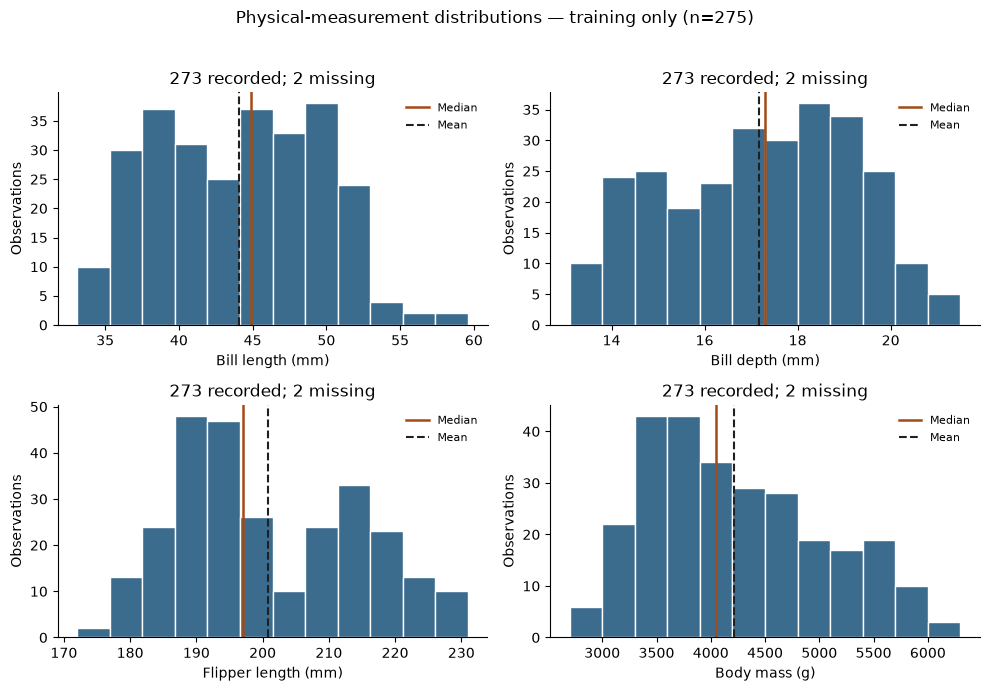

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, variable in zip(axes.flat, FEATURES):
    values = train[variable].dropna()  # Temporary plotting view, not a cleaned dataset.
    frequencies, edges, patches = ax.hist(values, bins=12, color='#3B6C8E', edgecolor='white')
    assert int(frequencies.sum()) == len(values)
    ax.axvline(values.median(), color='#A24B16', linewidth=1.8, label='Median')
    ax.axvline(values.mean(), color='#202020', linestyle='--', linewidth=1.5, label='Mean')
    ax.set(
        title=f'{len(values)} recorded; {int(train[variable].isna().sum())} missing',
        xlabel=MEASUREMENT_LABELS[variable], ylabel='Observations',
    )
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
fig.suptitle('Physical-measurement distributions — training only (n=275)')
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

**Interpretation.** Recorded bill lengths span 33.1–59.6 mm, bill depths 13.1–21.5 mm, flipper lengths 172–231 mm and body masses 2,700–6,300 g. Median flipper length is 197 mm and median mass is 4,050 g; their means are approximately 200.85 mm and 4,211.26 g. Means exceed medians for these two variables, but that difference alone does not establish a distribution family or identify erroneous values. We next separate the species to understand how their composition contributes to the pooled shapes.

## 18. Comparing physical measurements across species

**Question:** which groups differ, and how much do their observed values overlap?

The table reports each species' non-missing count, median, Q1 and Q3 for each measurement. A box spans Q1–Q3, its horizontal line is the median, and whiskers reach the most extreme observed values within 1.5 IQR of the quartiles. Points show **all** recorded values, including those beyond the whiskers. Horizontal jitter is a small, reproducible visual displacement to reduce overlap; it does not alter measurements or create new data. The box plot's separate outlier symbols are disabled only to avoid drawing the same observations twice.

Species labels are used for supervised EDA on training, not as classifier inputs. Box overlap is not an accuracy estimate, a hypothesis test or model feature importance. A point beyond a whisker is not automatically an error and will not be removed.

bill_length_mm                      bill_depth_mm                \
                   count median     Q1     Q3         count median     Q1   
species                                                                     
Adelie               121  39.00  36.80  40.80           121  18.40  17.50   
Chinstrap             54  49.95  46.42  51.30            54  18.60  17.82   
Gentoo                98  47.45  45.50  49.75            98  14.95  14.20   

                 flipper_length_mm                      body_mass_g          \
              Q3             count median     Q1     Q3       count  median   
species                                                                       
Adelie     19.00               121  190.0  185.0  194.0         121  3700.0   
Chinstrap  19.48                54  196.0  193.0  201.0          54  3712.5   
Gentoo     15.70                98  216.0  212.0  221.0          98  5075.0   

                            
                Q1      Q3  
species                     
Adelie     3325.00  4000.0  
Chinstrap  3500.00  4037.5  
Gentoo     4706.25  5500.0

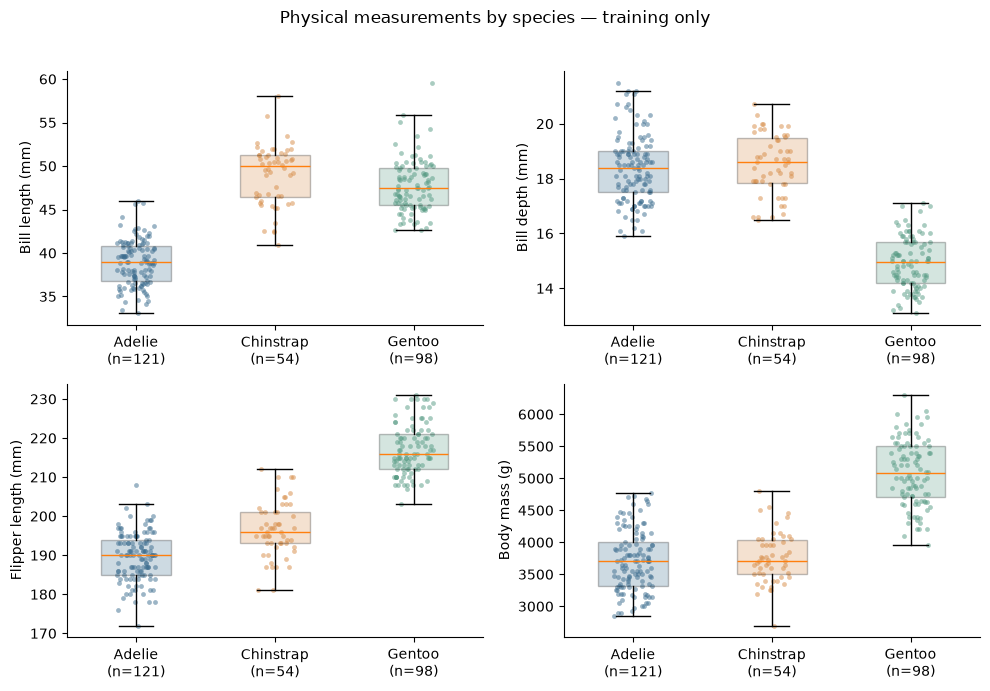

In [14]:
import numpy as np

species_measurement_summary = train.groupby(TARGET)[FEATURES].agg(
    ['count', 'median', lambda s: s.quantile(0.25), lambda s: s.quantile(0.75)]
).reindex(species_order)
species_measurement_summary.columns = pd.MultiIndex.from_tuples(
    [(variable, {'<lambda_0>': 'Q1', '<lambda_1>': 'Q3'}.get(stat, stat))
     for variable, stat in species_measurement_summary.columns]
)
display(species_measurement_summary.round(2))

rng = np.random.default_rng(SEED)
colours = ['#3B6C8E', '#D68B45', '#559A83']
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, variable in zip(axes.flat, FEATURES):
    groups = [train.loc[train[TARGET].eq(species), variable].dropna() for species in species_order]
    boxes = ax.boxplot(groups, positions=[1, 2, 3], widths=0.50,
                       whis=1.5, showfliers=False, patch_artist=True)
    for box, colour in zip(boxes['boxes'], colours):
        box.set_facecolor(colour)
        box.set_alpha(0.25)
    for position, values, colour in zip([1, 2, 3], groups, colours):
        jitter = rng.uniform(-0.14, 0.14, size=len(values))
        ax.scatter(position + jitter, values, s=12, alpha=0.50, color=colour, linewidths=0)
    ax.set_xticks([1, 2, 3], [f'{species}\n(n={len(values)})' for species, values in zip(species_order, groups)])
    ax.set(ylabel=MEASUREMENT_LABELS[variable])
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Physical measurements by species — training only')
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

### What can we learn without fitting a model?

- **Bill length:** training medians are 39.00 mm (Adelie), 49.95 mm (Chinstrap) and 47.45 mm (Gentoo). Adelie tends to have shorter bills, but observed ranges overlap. Chinstrap and Gentoo also overlap; bill length alone does not uniquely identify every observation.
- **Bill depth:** Gentoo has a lower median (14.95 mm) than Adelie (18.40 mm) or Chinstrap (18.60 mm). The latter two have similar centres, and the full observed ranges are not disjoint.
- **Flipper length:** Gentoo's median is 216 mm, versus 190 mm for Adelie and 196 mm for Chinstrap. Gentoo tends to have longer flippers, but neighbouring ranges still overlap.
- **Body mass:** Gentoo's median is 5,075 g, versus 3,700 g and 3,712.5 g for Adelie and Chinstrap. A higher group median does not mean that every Gentoo is heavier than every other penguin. Adelie and Chinstrap are particularly similar in this marginal comparison.

The recorded measurement counts are 121 Adelie, 54 Chinstrap and 98 Gentoo, because the two incomplete measurement rows remain in training but cannot contribute measured values to these panels. Group sizes differ, and sex or collection context may contribute to within-group variation. We have not yet disentangled those factors.

**Implication:** different measures appear to distinguish different groups. Combining them is a sensible hypothesis for later modelling, not demonstrated predictive performance. No variable is selected or discarded from these plots.

## 19. Looking at two measurements together

**Question:** what relationships and overlaps become visible when we combine measurements?

We show all six unique pairs of four measurements, rather than selecting only the most striking pair. Each point is one training observation with both measurements recorded. Species is used for colour and marker shape to help interpret groups, never as an input to a classifier. Axes retain original units, all observed extremes remain, and no line or predictive model is fitted. Missing values are excluded only from the temporary pair being plotted.

For this split, all six pairs have 273 recorded observations because the two missing measurement rows coincide. This is a property of this sample, not a general rule about pairwise missingness.

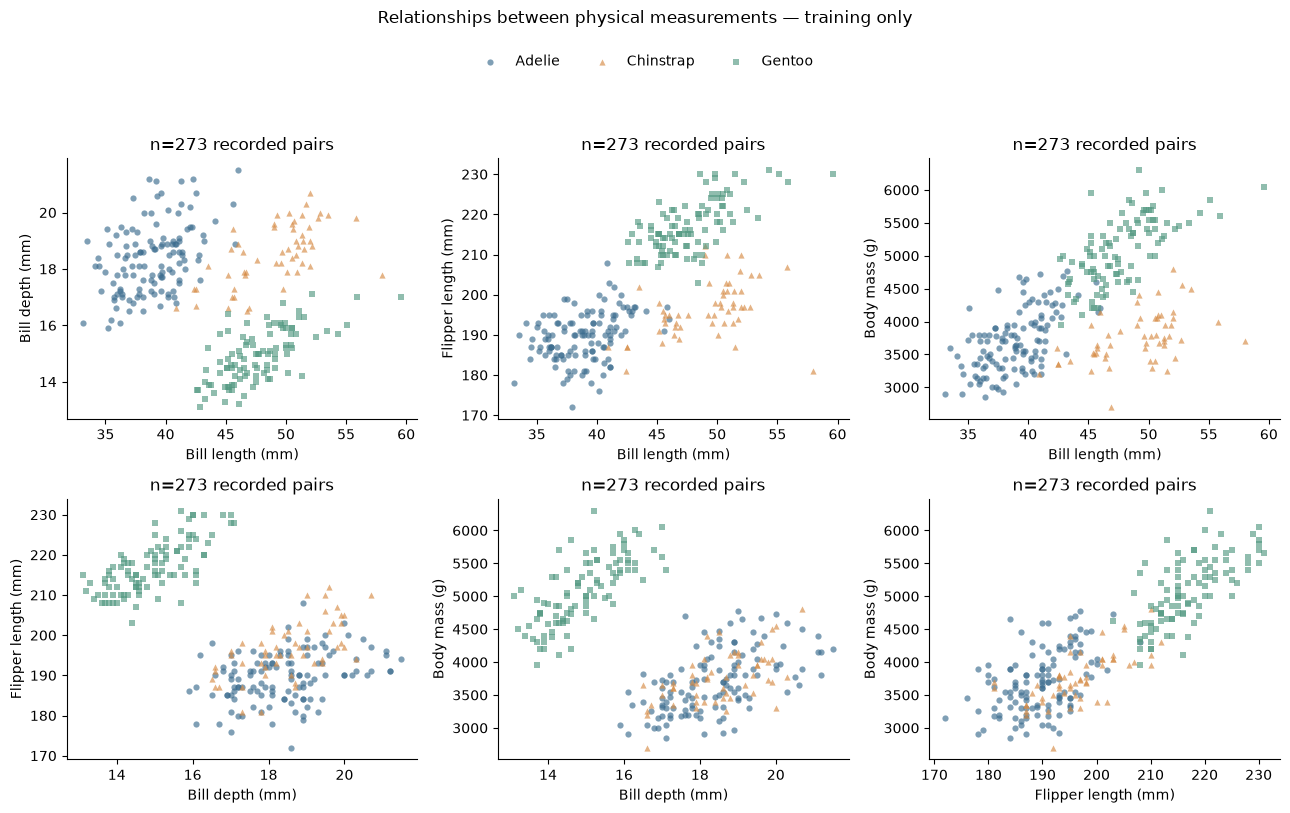

In [15]:
from itertools import combinations

MEASUREMENT_PAIRS = list(combinations(FEATURES, 2))
markers = ['o', '^', 's']
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (x_variable, y_variable) in zip(axes.flat, MEASUREMENT_PAIRS):
    paired = train[[x_variable, y_variable, TARGET]].dropna(subset=[x_variable, y_variable])
    assert set(paired.index).issubset(train_ids)
    for species, colour, marker in zip(species_order, colours, markers):
        group = paired.loc[paired[TARGET].eq(species)]
        ax.scatter(group[x_variable], group[y_variable], label=species,
                   color=colour, marker=marker, s=20, alpha=0.65, linewidths=0)
    ax.set(xlabel=MEASUREMENT_LABELS[x_variable], ylabel=MEASUREMENT_LABELS[y_variable],
           title=f'n={len(paired)} recorded pairs')
    ax.spines[['top', 'right']].set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.97))
fig.suptitle('Relationships between physical measurements — training only', y=1.01)
fig.tight_layout(rect=(0, 0, 1, 0.91))
plt.show()

**Interpretation.** Flipper length and body mass tend to increase together in the pooled sample, with Gentoo occupying much of the longer/heavier region. Bill length versus bill depth shows another useful pattern: Gentoo's generally shallower bills help distinguish it from Chinstrap despite their overlapping bill lengths. Adelie tends to occupy a shorter-bill region. There is still overlap and within-species variation. A visually promising combination is a hypothesis for later classification, not a measured score or proof of generalisation.

## 20. Summarising association: Pearson and Spearman

**Question:** how do we describe association numerically without treating it as feature importance?

**Pearson's r** measures linear association. It is the covariance divided by the product of the standard deviations, so it has no physical unit and lies between −1 and +1 when defined. Positive values indicate that larger values tend to occur together; negative values indicate opposite directions. A value near zero does not rule out a nonlinear relationship.

**Spearman's rho** is the Pearson correlation of the ranks, with average ranks for ties. It describes monotonic association and is less sensitive to the numerical size of extremes, but is not immune to unusual observations. Neither coefficient establishes causality, measures a variable's usefulness for species classification, or justifies deleting one of two correlated inputs automatically.

The table reports both coefficients and the valid count for every pair in the pooled **training** sample. We do not correlate arbitrary numeric species codes, and we do not calculate significance tests or select features by p-values.

In [16]:
correlation_rows = []
for x_variable, y_variable in MEASUREMENT_PAIRS:
    pair = train[[x_variable, y_variable]].dropna()
    correlation_rows.append({
        'x': x_variable, 'y': y_variable, 'recorded_pairs': len(pair),
        'Pearson_r': pair[x_variable].corr(pair[y_variable], method='pearson'),
        'Spearman_rho': pair[x_variable].corr(pair[y_variable], method='spearman'),
    })
pair_correlations = pd.DataFrame(correlation_rows).set_index(['x', 'y'])
display(pair_correlations.round(3))
assert pair_correlations['recorded_pairs'].eq(273).all()

recorded_pairs  Pearson_r  Spearman_rho
x                 y                                                         
bill_length_mm    bill_depth_mm                 273     -0.240        -0.216
                  flipper_length_mm             273      0.676         0.692
                  body_mass_g                   273      0.602         0.592
bill_depth_mm     flipper_length_mm             273     -0.594        -0.529
                  body_mass_g                   273     -0.483        -0.438
flipper_length_mm body_mass_g                   273      0.866         0.833

## 21. Pooled association versus association within each species

**Question:** does the overall correlation describe the relationship inside each group?

A pooled coefficient combines within-species variation and differences between species. We compare the pooled Pearson matrix with one matrix per species, using exactly the same variable order and colour range [−1, +1]. The diagonal is always one here because each non-constant measurement is correlated with itself; it is not a model score. Every matrix is symmetric, so its two halves repeat the same information.

We also show counts and coefficients for two interpretable examples: bill length–depth and flipper length–mass. All six pairs remain visible in the matrices. Grouping by species is descriptive stratification, not causal adjustment, and other factors such as sex may still contribute to the within-group patterns.

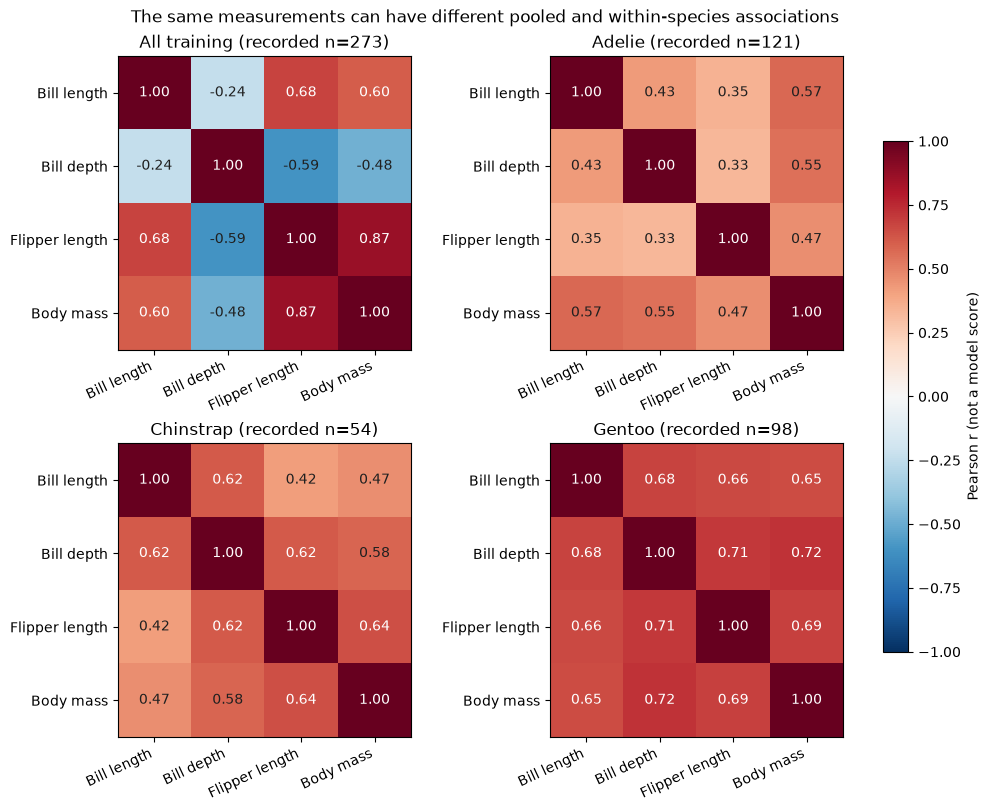

,,recorded_pairs,Pearson_r,Spearman_rho
pair,population,,,
bill_length_mm / bill_depth_mm,All training,273,-0.240,-0.216
flipper_length_mm / body_mass_g,All training,273,0.866,0.833
bill_length_mm / bill_depth_mm,Adelie,121,0.425,0.395
flipper_length_mm / body_mass_g,Adelie,121,0.465,0.452
bill_length_mm / bill_depth_mm,Chinstrap,54,0.617,0.622
flipper_length_mm / body_mass_g,Chinstrap,54,0.644,0.676
bill_length_mm / bill_depth_mm,Gentoo,98,0.679,0.652
flipper_length_mm / body_mass_g,Gentoo,98,0.687,0.700


In [17]:
populations = {'All training': train}
populations.update({species: train.loc[train[TARGET].eq(species)] for species in species_order})
pearson_matrices = {}
short_labels = ['Bill length', 'Bill depth', 'Flipper length', 'Body mass']
example_rows = []
examples = [('bill_length_mm', 'bill_depth_mm'), ('flipper_length_mm', 'body_mass_g')]
fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
for ax, (population_name, frame) in zip(axes.flat, populations.items()):
    matrix = frame[FEATURES].corr(method='pearson')
    pearson_matrices[population_name] = matrix
    complete_measurements = int(frame[FEATURES].notna().all(axis=1).sum())
    image = ax.imshow(matrix, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(4), short_labels, rotation=25, ha='right')
    ax.set_yticks(range(4), short_labels)
    ax.set_title(f'{population_name} (recorded n={complete_measurements})')
    for row in range(4):
        for column in range(4):
            value = matrix.iloc[row, column]
            ax.text(column, row, f'{value:.2f}', ha='center', va='center',
                    color='white' if abs(value) > 0.60 else '#202020')
    for x_variable, y_variable in examples:
        pair = frame[[x_variable, y_variable]].dropna()
        example_rows.append({'population': population_name, 'pair': f'{x_variable} / {y_variable}',
                             'recorded_pairs': len(pair),
                             'Pearson_r': pair[x_variable].corr(pair[y_variable]),
                             'Spearman_rho': pair[x_variable].corr(pair[y_variable], method='spearman')})
fig.colorbar(image, ax=axes, shrink=0.75, label='Pearson r (not a model score)')
fig.suptitle('The same measurements can have different pooled and within-species associations')
plt.show()
within_species_examples = pd.DataFrame(example_rows).set_index(['pair', 'population'])
display(within_species_examples.round(3))

### What did the comparison reveal?

**Bill length and depth reverse direction across aggregation levels.** Pooled Pearson r is approximately −0.240, but it is positive within Adelie (+0.425), Chinstrap (+0.617) and Gentoo (+0.679). The pooled scatter combines different group locations with their internal variation. This is an aggregation reversal often discussed as Simpson's paradox; it illustrates why an overall correlation should not be read as a universal biological relationship. It does not establish any causal mechanism.

**Flipper length and mass are positively associated at both levels**, but the pooled Pearson r (+0.866) exceeds the within-species values: +0.465 for Adelie, +0.644 for Chinstrap and +0.687 for Gentoo. The pooled Spearman value is +0.833, indicating the same overall monotonic direction. These statistics motivate the mass-regression comparison in notebook 02, but they do not measure its prediction error or show that one input is redundant.

The group-specific recorded counts are 121 Adelie, 54 Chinstrap and 98 Gentoo for every pair in this split. Different sample sizes and unexamined sex-related variation limit comparisons. Coefficients here are descriptive estimates, without confidence intervals or formal significance claims. They do not justify automatic feature deletion or causal arrows.

## 22. What has the EDA established?

The following evidence comes from the 275 training observations, not from the 69 reserved final-test observations. A descriptive result can motivate a modelling question without answering it.

1. **Class composition:** 122 Adelie, 54 Chinstrap and 99 Gentoo. We should examine errors for each class, not only overall accuracy. These counts do not predict how a classifier will behave.

2. **Missing measurements:** eleven rows have some absence, but only two lack classifier measurements; both lack all four. Eligibility should depend on the task-required variables. This does not establish random missingness or justify inventing measurements.

3. **Group differences:** Gentoo tends to be heavier with longer flippers, and different measures distinguish different groups. Combining measurements is worth testing, but the plots are not prediction scores or a feature ranking.

4. **Flipper length and mass:** pooled Pearson r is 0.866, with smaller positive within-species values. This motivates a regression comparison, not a causal claim or a predicted MAE.

5. **Aggregation reversal:** bill length–depth r is −0.240 pooled but positive within each species. Group composition matters; a global correlation is not a universal biological rule or a feature-removal criterion.

6. **Context:** island is associated with species in this sample; sex and year remain available for interpretation and a later justified comparison. This does not establish transfer to new islands, years or populations.

**Conclusion of the EDA:** the dataset supports clear learning questions. It has not yet demonstrated predictive performance. All eight variables remain available for study.

## 23. Preparation decisions used in supervised learning

The EDA informs the following procedure, implemented in notebook 02. This notebook itself performs no model fitting and does not alter the CSV.

1. Preserve the original source and the fixed 275/69 development/final-test allocation.
2. For classification, use four physical inputs with species as response. For regression, use three physical inputs with body mass as response; mass and species are not regression inputs.
3. Create separate task-specific complete-input/response views within training. Both currently contain 273 rows, excluding source IDs 3 and 271 from these views only. Missing sex alone excludes no observation. Do not fill missing responses as ground truth.
4. Keep recorded extremes and correlated inputs. No automatic p-value or correlation cutoff is used.
5. Fit scaling inside each logistic/SVM fit fold. The shallow tree and initial unregularised OLS retain original units. No imputation is required by these complete-case comparisons.
6. Retain island, sex and year in the source for context. Adding them to prediction would require a justified availability and validation comparison.

The two incomplete rows lack all four physical measurements; median filling would create entirely synthetic profiles. Complete-case evaluation has its own limitation: it describes only observations with required measurements. When final testing is eventually performed, report reserved, excluded and evaluated counts using the pre-agreed rule. Test eligibility has not been inspected.

Unsupervised learning remains planned: fit on complete physical training measurements without species or context labels, then interpret groups separately. No clustering or final-test analysis occurs in either current notebook.

## 24. Evaluation used in notebook 02

- **Classification:** five saved StratifiedKFold groups, shuffled with seed 42; the reference, logistic classifier, shallow tree and linear SVM share these folds. Read confusion counts, accuracy and precision/recall/F1 by species, followed by the equal-weight F1 mean (macro-F1).
- **Regression:** a separate shuffled KFold list, five splits and seed 42, compares a fit-median reference and OLS on the same 273 eligible rows. MAE in grams is primary, RMSE secondary and R-squared supplementary. Continuous mass is not stratified.
- **Learning:** each model and any scaler learn from the fit part of their fold only. Validation rows are predicted without refitting. Every eligible observation is held out once per method.
- **Depth selection:** notebook 02 also compares tree depths 2, 3, 4 and 5, keeping minimum leaf size 5. GridSearchCV uses the same development folds and mean species F1. Its selected score is not an independent assessment. No final all-training refit is performed.
- **Final testing:** the 69 reserved observations remain outside EDA, preparation choices, tuning and reported scores. Earlier whole-table ingestion checks are disclosed, so the test is not described as historically untouched. Freeze the eventual limited comparisons before opening it.

Pearson r describes association between two variables. The regression R-squared evaluates prediction error relative to the scored observations' mean; it is not automatically the square of an input/response correlation for multiple regression and held-out predictions.

Method references: [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [pipelines and leakage](https://scikit-learn.org/stable/common_pitfalls.html).

## 25. Conclusion and next task

The EDA describes the source, data quality, sample composition, distributions and relationships. It supports the choice of learning questions, but the plots and correlations do not measure predictive performance or show causal effects.

Notebook 02 applies the documented preparation rules, compares classification and regression methods using five-fold validation, and includes a small tree-depth search. The original CSV remains unchanged. Unsupervised learning and final testing are planned for the final submission.

AI assistance was used to draft explanations and code. The author is responsible for reviewing, understanding and explaining the submitted work. No personal learning reflection is claimed on his behalf.
